# Solución AY15 - Ejercicios de Networking y Arquitectura Cliente-Servidor (IIC2233)

## Pautas y distribución de puntaje

Las soluciones son de referencia: cualquier alternativa que cumpla el enunciado y esté justificada es válida. Los cálculos de bytes, los outputs de 6.1 y los resultados de JSON fueron verificados ejecutando el código.

### Pauta Pregunta 1

**A.1 (0.75 pts).** Imprime `{'1': ['Dune', 'Herbert'], 'disponible': True, 'dueño': None}` y luego `False`.

- (0.25) La llave `1` vuelve como `'1'`: en JSON las llaves de un objeto siempre son strings.
- (0.25) La tupla vuelve como lista: JSON no tiene tuplas.
- (0.25) Concluye que son distintos (`False`). `True`, `None` y `ñ` sí se recuperan igual.

**A.2 (0.75 pts).** El hook se aplica de adentro hacia afuera y su retorno reemplaza al objeto:

1. `{}` → 0
2. `{'d': 0, 'e': 0}` → 2
3. `{'b': 0, 'c': [1, 2]}` → 2
4. `{'a': 2, 'f': 2}` → 2

`resultado = 2`. (0.5) orden correcto de los cuatro diccionarios; (0.25) valor final.

**B.1 (0.5 pts).** `pickle` levanta `TypeError: cannot pickle 'socket' object`. Un socket representa una conexión abierta del sistema operativo en ese proceso; en otra ejecución esa conexión no existe.

**B.2 (0.5 pts).**

```python
def __getstate__(self):
    estado = self.__dict__.copy()      # copia: el original conserva su socket
    del estado["socket"]
    return estado

def __setstate__(self, estado):
    estado["socket"] = None
    estado["conectado"] = False
    self.__dict__ = estado
```

(0.25) `__getstate__` con copia y sin socket; (0.25) `__setstate__` que asigna `self.__dict__`. Sin `.copy()`, se descuenta 0.1.

**B.3 (0.5 pts).** `pickle.loads` sobre bytes de otro programa puede ejecutar código arbitrario en el servidor. Se usa JSON (con un formato acordado), que solo produce datos.

**C.1 (0.5 pts).** Host `api.dccanje.cl`; puerto `8443`; ruta `/libros/42/resenas`; query `pagina=2`, `orden=fecha`; el fragmento `#comentarios` no se envía. (0.1 por elemento.)

**C.2 (0.5 pts).** 1/16 de punto por código:

| Código | Tipo | Significado |
| --- | --- | --- |
| 201 | Éxito | Recurso creado |
| 204 | Éxito | Sin contenido en la respuesta |
| 401 | Cliente | Falta autenticación o es inválida |
| 404 | Cliente | El recurso no existe |
| 405 | Cliente | Método no permitido en esa ruta |
| 422 | Cliente | Formato correcto, pero valores inválidos |
| 429 | Cliente | Demasiadas solicitudes (*rate limit*) |
| 503 | Servidor | Servicio no disponible |

**D.1 (0.5 pts).** Posiciones: UDP; solo importa la última posición y retransmitir una vieja no sirve. Chat: TCP; garantiza entrega y orden.

**D.2 (1 pt).** TCP es un flujo de bytes: `recv` entrega lo que haya llegado hasta ese momento, como máximo 4096, y el mensaje puede llegar en varios segmentos. `b""` indica que la otra parte cerró la conexión.

**D.3 (0.5 pts).** `send` puede enviar solo una parte y retorna cuántos bytes envió, hay que repetirlo con el resto. `sendall` reintenta hasta enviar todo. Si `sendall` falla, solo levanta la excepción y no se sabe cuántos bytes alcanzaron a enviarse.

### Pauta Pregunta 2

**2.1 (2 pts).** Payload: `48 6F 6C 61 2C 20 C3 B1 61 6E 64 C3 BA`.

- (0.5) 11 caracteres y 13 bytes: en UTF-8, `ñ` y `ú` ocupan 2 bytes cada una.
- (0.5) Header: `0D 00 03` (13 en little endian = `0D 00`; 3 chunks porque 13 = 6 + 6 + 1).
- (0.5) Último bloque: `03 BA 00 00 00 00 00`.
- (0.5) Total: 3 + 3 × (1 + 6) = **24 bytes**.

**2.2 (2 pts).** (0.5) Largo `08 00` = 8 y 2 chunks. (0.5) Payload `C2 BF 4C 69 62 72 6F 3F` = `¿Libro?`. (0.5) Se necesita el largo real para quitar el relleno: un `00` de relleno no se distingue de un `00` legítimo del mensaje.

**2.3 (2 pts).**

```python
def recibir_exacto(sock, n):
    datos = bytearray()
    while len(datos) < n:
        parte = sock.recv(n - len(datos))
        if parte == b"":
            raise ConnectionError("conexión cerrada a mitad del mensaje")
        datos.extend(parte)
    return bytes(datos)

def recibir_texto(sock):
    header = recibir_exacto(sock, 3)
    largo = int.from_bytes(header[:2], "little")
    cantidad = header[2]
    payload = bytearray()
    for esperado in range(1, cantidad + 1):
        numero = recibir_exacto(sock, 1)[0]
        if numero != esperado:
            raise ValueError("chunk fuera de orden")
        payload.extend(recibir_exacto(sock, 6))
    return bytes(payload[:largo]).decode("utf-8")
```

(0.5) lee exacto con ciclo y detecta `b""`; (0.5) interpreta el header en little endian; (0.25) verifica el orden; (0.25) recorta al largo real y decodifica.

### Pauta Pregunta 3

**3.1 (2 pts).**

```python
@app.route("/libros", methods=["GET"])
def listar():
    autor = request.args.get("autor", default=None, type=str)
    limite = request.args.get("limite", default=10, type=int)
    with lock_libros:
        libros = [l for l in LIBROS.values() if autor is None or l["autor"] == autor]
    return {"libros": libros[:limite]}

@app.route("/libros", methods=["POST"])
def crear():
    datos = request.get_json(silent=True)
    if not isinstance(datos, dict) or not {"titulo", "autor"} <= datos.keys():
        return {"error": "faltan titulo o autor"}, 400
    if not all(isinstance(datos[k], str) and datos[k].strip() for k in ("titulo", "autor")):
        return {"error": "titulo y autor deben ser textos no vacíos"}, 422
    with lock_libros:
        nuevo_id = max(LIBROS, default=0) + 1
        LIBROS[nuevo_id] = {"id": nuevo_id, "titulo": datos["titulo"],
                            "autor": datos["autor"], "estado": "disponible"}
        return LIBROS[nuevo_id], 201
```

(0.75) GET con `request.args`, valor por defecto y tipo; (0.75) POST con validación 400/422 y respuesta 201; (0.5) el id se genera bajo lock (con `threaded=True`, dos POST podrían obtener el mismo id).

**3.2 (1 pt).**

```python
def buscar_por_autor(autor):
    try:
        r = requests.get(URL + "/libros", params={"autor": autor, "limite": 5}, timeout=5)
        r.raise_for_status()
    except requests.RequestException:
        return []
    if not r.headers.get("Content-Type", "").startswith("application/json"):
        return []
    return r.json()["libros"]
```

(0.25) `params=`; (0.25) `timeout`; (0.25) maneja error HTTP y de conexión; (0.25) revisa `Content-Type`.

**3.3 (1.5 pts).** 0.25 por fila:

| Solicitud | Código | Por qué |
| --- | --- | --- |
| `json={"titulo": "Dune"}` | 400 | Falta la llave `autor` |
| `titulo` vacío | 422 | Llaves presentes, valor inválido |
| `data={...}` | 400 | Es un formulario, `get_json(silent=True)` da `None`. Con `get_json()` sin `silent`, Flask responde 415: también es correcto si se justifica |
| `GET /libros/7` | 405 | La ruta existe (por `DELETE`), pero no acepta GET |
| `PUT /libros` | 405 | La ruta existe, sin ese método |
| `DELETE /libros/abc` | 404 | `abc` no calza con `<int:id>`: no hay ruta |

**3.4 (1.5 pts).**

- (0.5) *Lost update* / verificar-y-actuar: el thread 1 lee `disponible`, entra a `registrar_auditoria`; el thread 2 lee `disponible` antes de que el 1 escriba; ambos escriben `reservado` y responden `True`. Corrección: verificar y cambiar el estado dentro del mismo `with lock_libros:`.
- (0.5) Cliente: deshabilitar el botón al primer clic. Servidor: con la verificación bajo lock, el segundo POST recibe `409`; además se puede aceptar un `Idempotency-Key` y repetir la primera respuesta. El cliente solo no basta: hay reintentos de red, otros clientes y clientes modificados.
- (0.5) No: un `threading.Lock` vive en un proceso y no se comparte. Se necesita una operación atómica o transacción en una base de datos compartida.

### Pauta Pregunta 4

**Supuestos de la solución de referencia**

| Agregado | Justificación |
| --- | --- |
| `RESPONDER` lleva `id_pregunta` | Una respuesta atrasada a la pregunta anterior no debe contar para la actual |
| Un thread de partida en el servidor que espera con `evento_todos.wait(timeout=15)` | Una sola espera cubre los dos cierres: “todos respondieron” (`set()`) y “venció el plazo” (timeout) |
| Un `lock_envio` por cliente en el servidor | El thread del cliente responde y el thread de partida difunde por el mismo socket |
| El cliente recibe en un `QThread` y envía desde el thread principal | `recv` bloquea; enviar mensajes pequeños es rápido |

**4.1 Diagrama del sistema (10 pts)**

- (3 pts) Servidor con thread principal (`accept`), un thread por cliente y el thread de partida (o un `threading.Timer` por pregunta).
- (3 pts) Cada cliente con front-end y back-end en el thread principal y un `QThread` receptor. Las señales tienen nombre y argumentos, por ejemplo `senal_responder(str)`, `senal_mensaje(dict)`, `senal_puntajes(dict)`, `senal_desconectado()`.
- (2 pts) Socket: comandos cliente → servidor, respuesta solo a quien preguntó, eventos (`PREGUNTA`, `RESULTADO`, `CHAT`, `JUGADOR_SALIO`) a todos.
- (2 pts) Formato: JSON en UTF-8 con header de 4 bytes big endian. Basta indicarlo una vez.

**4.2 Threads y timers (10 pts)**

| Dónde | Mecanismo | Qué hace | Cuándo inicia / quién llama `start()` |
| --- | --- | --- | --- |
| Servidor | Thread principal | `bind`, `listen` y ciclo de `accept` | Al ejecutar el programa (lo inicia el intérprete) |
| Servidor | `Thread` por cliente | Recibe mensajes de ese cliente, procesa `UNIRSE`, `RESPONDER` y `CHAT`, y responde | Al aceptar la conexión; lo inicia el thread principal |
| Servidor | `Thread` de partida | Envía la pregunta, espera `evento_todos.wait(timeout=15)`, cierra, difunde `RESULTADO`, `sleep(5)`, repite | Cuando se une el 2° jugador; lo inicia el thread de ese cliente |
| Cliente | Thread principal | Event loop: front-end, back-end, envíos | Al ejecutar `app.exec()` |
| Cliente | `QThread` receptor | Ciclo de `recibir` y `senal_mensaje.emit(dict)`; ante error, `senal_desconectado.emit()` | Tras `connect`; lo inicia el back-end en el thread principal y guarda la referencia |
| Cliente | `QTimer` (100 ms) | Descuenta 0,1 s y emite el tiempo restante al front-end | Al llegar `PREGUNTA` (`start`); se detiene con `RESULTADO` |

- (2 pts) Cuenta regresiva: es periódica y rápida, así que `QTimer` corre en el thread principal sin concurrencia ni código de detención. Un thread con `sleep` obligaría a usar señales, una bandera y `wait()` para detenerlo. Hacer `sleep` en un slot congela la ventana.
- (2 pts) El servidor no tiene `QApplication` ni event loop; un `QTimer` necesita el event loop de su thread para emitir `timeout`.
- (2 pts) Recursos del servidor: estado de la partida (jugadores, puntajes, pregunta actual, conjunto de quienes respondieron, si ya hubo una correcta, `cerrada`) bajo `lock_partida`; escritura de cada socket bajo su `lock_envio`. Para difundir, se copia la lista de jugadores dentro de `lock_partida` y se envía fuera de él.
- (2 pts) El cliente no necesita locks: el `QThread` solo lee el socket y emite señales; todo el estado se modifica en slots que corren en el thread principal (conexiones encoladas); solo el thread principal escribe en el socket.
- (2 pts) Tabla completa y coherente.

**4.3 Diagrama de señales (14 pts)**

Pasos de referencia (el diagrama siguiente los dibuja):

1. [Ana · principal] `boton_b.clicked` → slot de `Ventana`: deshabilita los 4 botones y emite `senal_responder("B")`.
2. [Ana · principal] `Logica.enviar_respuesta("B")` ejecuta `enviar(sock, {"tipo": "RESPONDER", "id_pregunta": 7, "opcion": "B"})`. La cuenta regresiva de Ana sigue corriendo.
3. [Servidor · thread de Ana] lee 4 bytes de header y luego exactamente `largo` bytes; `json.loads`.
4. [Servidor · thread de Ana] `with lock_partida:` verifica que la 7 sea la actual, no esté cerrada ni vencida y que Ana no haya respondido; es la primera correcta, así que suma 3 puntos; agrega a Ana a quienes respondieron; como ya respondieron todos, llama `evento_todos.set()`. Suelta el lock.
5. [Servidor · thread de Ana] `with lock_envio[Ana]:` envía `RESPUESTA_RECIBIDA(7, aceptada=True)`.
6. [Servidor · thread de partida] `wait` retorna antes de 15 s. `with lock_partida:` marca la 7 como cerrada (desde ahora toda respuesta a la 7 se rechaza) y copia puntajes y jugadores. Suelta el lock. El plazo de 15 s ya no aplica.
7. [Servidor · thread de partida] para cada jugador, `with lock_envio[j]:` envía `RESULTADO(7, "B", {"Ana": 3, "Bruno": 0})`.
8. [Bruno · QThread receptor] `recibir` completa el mensaje y emite `senal_mensaje(dict)`; la llamada se encola en el thread principal.
9. [Bruno · principal] `Logica.procesar_mensaje`: tipo `RESULTADO` → `timer_cuenta.stop()` y emite `senal_puntajes(dict)` y `senal_correcta("B")`.
10. [Bruno · principal] `Ventana.actualizar_puntajes(dict)` actualiza la tabla. En Ana ocurre lo mismo con su propio `RESULTADO`.

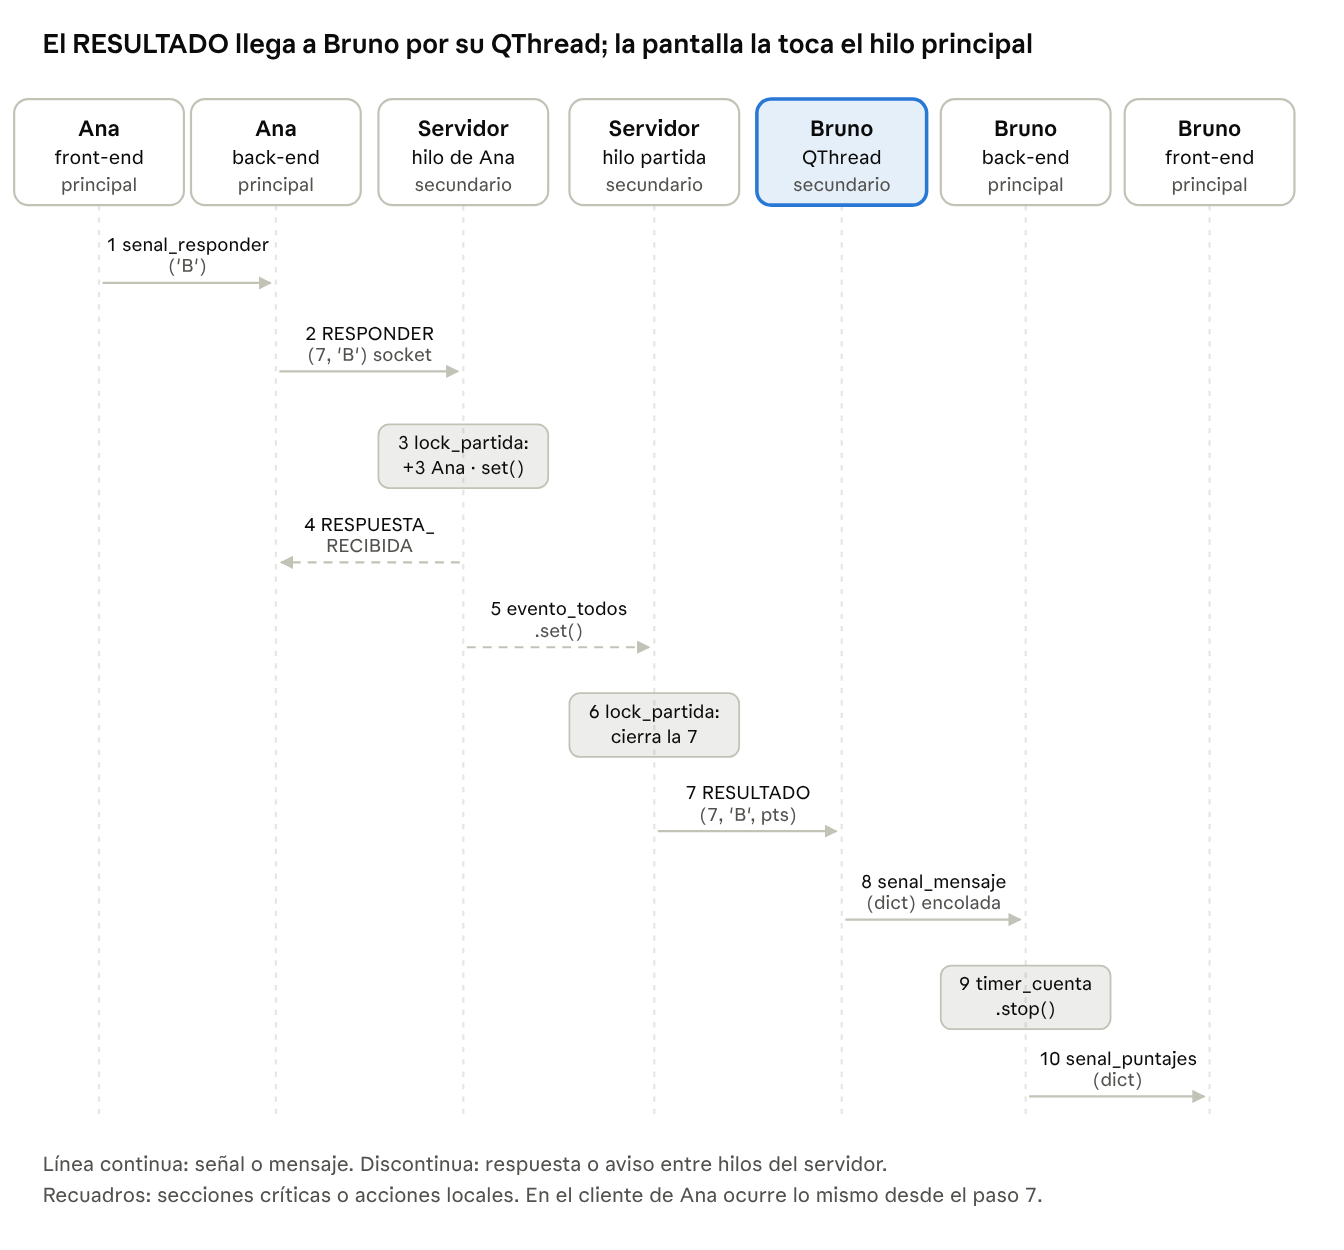

*Diagrama de secuencia de referencia para 4.3 · 10 pasos, 7 hilos*

El único objeto que corre fuera del hilo principal en los clientes es el QThread receptor, y solo emite señales; los locks del servidor se toman en tramos cortos.

Distribución: (3) señales del cliente con nombre, argumentos y thread correcto; (3) mensajes por socket con tipo y contenido; (3) locks del servidor tomados en tramos cortos, verificación y cambio en la misma sección crítica; (2) cierre por “todos respondieron” y qué pasa con el plazo; (2) el thread receptor nunca toca widgets; (1) la cuenta regresiva se detiene con `RESULTADO`, no con el clic.

**4.4 Análisis de código (8 pts)** 4/3 de punto por error, hasta 8:

| Error | Síntoma | Corrección |
| --- | --- | --- |
| `run` hace `label_pregunta.setText` | Viola la regla de oro: fallas aleatorias o `Segmentation fault` | Emitir `senal_mensaje(dict)` y que el thread principal actualice |
| `QTimer()` creado dentro de `run` | Vive en el thread del QThread, que no tiene event loop: `timeout` nunca se emite | Crear el `QTimer` en el back-end (thread principal) |
| `hilo` es variable local | `QThread: Destroyed while thread is still running` y `Aborted` | `self.hilo = EscucharThread(...)` |
| `enviar_respuesta` hace `recibir` | Bloquea el thread principal (la ventana se congela) y compite con el QThread por el mismo socket: cada uno recibe mensajes del otro | Solo el QThread recibe; la respuesta llega como `senal_mensaje` |
| `señal_resultado` con `ñ` | El nombre de la señal debe ser ASCII | `senal_resultado` |
| `connect(self.responder("A"))` | Llama al método al construir la ventana y conecta su retorno (`None`) | `connect(lambda: self.responder("A"))` |
| `closeEvent` sin limpieza | El QThread queda bloqueado en `recv` al cerrar | `shutdown` + `close` del socket y `hilo.wait()` (o `app.aboutToQuit`) |
| `run` sin `try/except` | Si se cae el servidor, la excepción mata el thread y la ventana nunca se entera | Capturar `ConnectionError`/`OSError` y emitir `senal_desconectado` |
| `EscucharThread` recibe la ventana | Acopla el back-end al front-end | El thread solo conoce el socket y emite señales |

**4.5 Situaciones (8 pts)**

1. (2) `recv` retorna `b""` o lanza `ConnectionResetError` → `recibir` levanta `ConnectionError` → el QThread emite `senal_desconectado` y termina su `run` → el back-end detiene el `QTimer` y avisa al front-end → la ventana muestra “Se perdió la conexión” y deshabilita botones. Nada se congela.
2. (2) Cliente: en `closeEvent` o `aboutToQuit` hace `shutdown` (despierta el `recv` bloqueado), `close` y `wait()` del QThread. Servidor: el thread de Ana recibe `b""`, en su `finally` saca a Ana de jugadores bajo `lock_partida`, cierra el socket y difunde `JUGADOR_SALIO`; si solo quedaba Ana por responder, hace `evento_todos.set()`.
3. (2) Recibe 3 puntos quien entra primero a la sección crítica de `lock_partida`, no quien hizo clic primero. Como la verificación “ya hubo una correcta” y el cambio ocurren en el mismo `with`, no pueden recibir 3 ambos. Si vence el plazo mientras se procesa a Ana, el thread de partida espera el lock; Ana ya fue verificada dentro del plazo y cuenta. Después se marca `cerrada`.
4. (2) No es un error: el servidor es la autoridad sobre el plazo, porque los relojes de los clientes difieren y la red tarda. La cuenta regresiva local solo informa. El rechazo llega como `RESPUESTA_RECIBIDA(aceptada=False, motivo)`.

**Bonus (+2).** Por defecto `json.dumps` usa `ensure_ascii=True`: cada carácter no ASCII se escribe como una secuencia de escape de 6 caracteres ASCII (barra invertida, `u` y 4 dígitos hexadecimales: `u00a1` para `¡` y `u00ed` para `í`). El JSON con `¡Sí!` en texto plano ocupa 49 bytes ASCII; cada uno de los 2 caracteres especiales pasa de 1 carácter a 6, así que el payload tiene **59 bytes** y el header es `00 00 00 3B`. Con `ensure_ascii=False` se codificarían en UTF-8 (2 bytes cada uno) y serían 51 bytes.

### Pauta Pregunta 5

**Supuestos de la solución de referencia**

| Agregado | Justificación |
| --- | --- |
| Respuestas `PUJA_ACEPTADA` / `PUJA_RECHAZADA(motivo)` solo a quien pujó | El usuario necesita saber el resultado de su puja |
| Timeout de 7 s en la llamada a DCCBanco | Mayor que el máximo de 6 s del enunciado |
| Una `Queue` y un thread emisor por cliente | Un cliente lento no debe bloquear al thread que difunde |
| `cierre` viaja como hora absoluta (ISO 8601) | Cada cliente calcula su cuenta regresiva local |

**5.1 (12 pts)**

- (6) Diagrama: cliente ↔ servidor de subastas (comandos, respuestas y eventos, JSON + header); cliente ↔ servidor de chat (mismo formato); subastas → DCCBanco (HTTP `GET /saldo/<usuario>`) y respuesta `200 {"saldo": int}`, `503` o nada; subastas → `adjudicaciones.csv` (CSV); navegador → API (`GET /subastas/<id>/historial`) y respuesta JSON.
- (6) El cliente tiene **2 sockets** y **2 QThreads receptores**, uno por socket, que el back-end inicia y guarda. Un solo thread alternando no sirve: `recv` es bloqueante, así que mientras espera en el socket de subastas no lee el de chat, y viceversa. El back-end distingue el origen porque cada QThread emite una señal distinta (`senal_subasta(dict)`, `senal_chat(dict)`) conectada a un slot distinto. Ambos envíos se hacen desde el thread principal.

**5.2 (12 pts)**

| Thread | Qué hace | Cuándo / quién llama `start()` |
| --- | --- | --- |
| Principal | `bind`, `listen`, ciclo de `accept` | Al ejecutar el servidor |
| Receptor por cliente | Lee mensajes y procesa `PUJAR` (incluida la llamada a DCCBanco) | Al aceptar la conexión; el principal |
| Emisor por cliente | `cola.get()` y `sendall` hacia ese cliente | Al aceptar la conexión; el principal |
| Vigilante de cierres | Cada 0,5 s revisa qué subastas vencieron, las cierra, escribe el CSV y difunde `SUBASTA_CERRADA` | Al iniciar el servidor; el principal |
| Flask | `app.run(threaded=True)`; un thread por request | Al iniciar el servidor; el principal |

Recursos: subastas (puja máxima, usuario, cierre, historial) con `lock_subastas`; lista de clientes con `lock_clientes` (se copia y se difunde fuera); `adjudicaciones.csv` con `lock_archivo`; cada `Queue` ya es thread-safe y solo su thread emisor escribe en el socket, así que no se necesita `lock_envio`.

Comparación (4 de los 12 pts): con `threading.Timer` hay que cancelar y crear uno nuevo en cada extensión, y un timer viejo que ya se disparó puede estar esperando el lock; su callback debe verificar bajo lock que `ahora >= cierre`. El vigilante es un solo thread, no se reemplaza nada y siempre compara contra el cierre vigente, con un error de hasta 0,5 s. Se acepta cualquiera de las dos si se justifica y se cubre la carrera.

Distribución: (4) threads con qué/cuándo/quién; (4) recursos y su protección; (4) comparación de cierres.

**5.3 (16 pts)**

1. (3) [Servidor · receptor de Pedro] lee 4 bytes de header y luego `largo` bytes en un ciclo; `json.loads`.
2. (3) `with lock_subastas:` verifica que S-3 esté abierta y que 9000 ≥ 8000 + 500. Suelta el lock. **No** se llama a DCCBanco con el lock tomado: bloquearía todas las pujas hasta 6 s.
3. (2) Sin locks: `requests.get(BANCO + "/saldo/pedro", timeout=7)`; el saldo alcanza.
4. (3) `with lock_subastas:` **vuelve a verificar** que S-3 siga abierta y que 9000 siga superando la máxima en $500, porque en esos 2 s pudo cerrar o llegar otra puja. Acepta: máxima 9000, usuario Pedro, agrega al historial. Quedan 4 s, que es menos de 10: `cierre = ahora + 10`. Suelta el lock.
5. (3) Encola `PUJA_ACEPTADA` en la cola de Pedro. Con `lock_clientes` copia la lista, suelta y encola `NUEVA_PUJA("S-3", 9000, "pedro", cierre)` en la cola de cada cliente. Encolar no bloquea; el emisor de Rosa tarda en su `sendall`, pero solo retrasa a Rosa.
6. (2) [Rosa · QThread de subastas] completa el mensaje y emite `senal_subasta(dict)` → [Rosa · principal] `Logica.procesar_subasta` actualiza su modelo y emite `senal_nueva_puja(...)` → la `Ventana` actualiza la puja y reinicia la cuenta regresiva (`QTimer`) con el nuevo cierre.

**5.4 (10 pts)**

1. (3) El lock no está tomado durante la consulta de Pedro: la puja de Quena se acepta a los 0,2 s (máxima $9.500) y se difunde. Cuando DCCBanco responde a Pedro, la re-verificación falla (9000 < 9500 + 500) y Pedro recibe `PUJA_RECHAZADA("puja superada")`.
2. (3) A los 7 s se lanza `requests.Timeout`; se trata como saldo no confirmado: Pedro recibe `PUJA_RECHAZADA("banco no disponible")`, la subasta no cambia y nadie quedó bloqueado. Un `503` se trata igual.
3. (2) El QThread de chat recibe `b""`, emite `senal_chat_desconectado` y la ventana deshabilita el chat con un aviso. Las subastas siguen: otro socket, otro thread, otro servidor.
4. (2) No, si Flask copia el historial bajo `lock_subastas`: la puja se agrega dentro de esa misma sección crítica, así que el navegador ve el historial antes o después de la puja, nunca a medias.

### Pauta Pregunta 6

**6.1 (2 pts).** 0.25 por línea en orden; –0.5 si aparece `B-fin`.

```text
S-escuchando      t = 0
A-conecta         t = 1
S-procesa         t = 1
B-conecta         t = 2,8
A-envia           t = 3    (esperó el lock desde 1,5)
S-responde        t = 3,5
B-envia           t = 4    (esperó el lock desde 3,3)
A-fin             t = 4,5
main-fin          t = 4,5
```

`B-fin` (que sería en t = 5,5) no se imprime: `b` es daemon, `main` solo hace `join` de `s` y `a`, y el programa termina en 4,5.

**6.2 (1.5 pts).**

```text
[run] secundario          t ≈ 0
[mostrar] 0 principal     t ≈ 1
[pausar] principal        t ≈ 1,5
[mostrar] 1 principal     t ≈ 3,5   (emitida en 2, encolada)
[mostrar] 2 principal     t ≈ 3,5   (emitida en 3, encolada)
```

(0.5) Output y tiempos. (0.5) La descarga no se pausa: `run` sigue en su thread. `pausar` es un slot de un objeto que vive en el thread principal, así que la ventana se congela 2 s y los progresos 1 y 2 aparecen juntos. (0.5) Corrección: `pausar` solo cambia una bandera (`self.pausado = True`, o un `threading.Event`) y `run` la revisa en su ciclo; el `sleep` va dentro de `run`.

**6.3 (1 pt).** Ticks en t = 1 y 2; `stop` en 2,5; `start` en 4,2 reinicia el intervalo; ticks en 5,2 y 6,2; en t = 7 imprime **4** (0.5). Con `timer = QTimer()` local y sin padre, el objeto se destruye al terminar `__init__`: nunca emite `timeout` e imprime 0 (0.5).

**6.4 (1.5 pts).** 0.3 por error y 0.3 por el valor:

1. `enviados = sock.send(...)` debe ser `+=`: si `send` envía parcial, se reenvían bytes equivocados o el ciclo no termina.
2. `sock.recv(4)` puede entregar menos de 4 bytes: hay que leer en un ciclo hasta tener 4.
3. Se lee en `"little"` y se escribió en `"big"`: el largo queda mal.
4. `sock.recv(largo)` puede entregar solo una parte del mensaje, y nunca se revisa `b""` (conexión cerrada).

Para 300 bytes el header es `00 00 01 2C`; leído en little endian da 0x2C010000 = **738 263 040**.